# Guardar el significado

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---

| | |
|---|---|
| **Problema** | Para encontrar fragmentos por significado hay que convertirlos en vectores y guardarlos de modo que una consulta se pueda comparar con todos. Mezclar modelos o olvidar un prefijo rompe la búsqueda sin dar ningún error. |
| **Producto** | Una colección persistente de cuentos con consultas y filtros, la función `buscar` y una regla para no mezclar modelos. |
| **Recursos** | Modelo de embeddings `multilingual-e5-small` (unos 470 MB; carga en unos segundos). El modelo `paraphrase-multilingual-MiniLM-L12-v2` (otros 470 MB, el de la unidad 009) se usa en una sola sección. Sin Ollama ni claves. |

El equipo de una biblioteca digital tiene 137 fragmentos de cuentos y quiere que una persona escriba «alguien intenta quitarse la vida» o «quién prepara la comida» y obtenga los textos que tratan eso, aunque no usen esas palabras. Un buscador por palabras no alcanza. Hace falta guardar, junto a cada fragmento, un vector que represente su significado.

**¿Cómo se guarda y se consulta el significado de un texto, y qué puede salir mal sin que el programa avise?**

> **Cómo se trabaja.** En clase se presenta cada tema con el código ya escrito. Después lo explorás por tu cuenta: ejecutás las celdas, leés las notas **Para mirar** y cambiás valores para ver qué pasa. Al final de cada bloque hay un **microlaboratorio**: una tabla te dice qué líneas completar y con qué, y la celda siguiente comprueba si quedó bien.

## Los datos

| Campo | Dato |
|---|---|
| Fuente | `datos/cuentos/fragmentos.csv`, de la unidad 009: 137 fragmentos de 34 cuentos y minicuentos latinoamericanos, compilados a partir de ciudadseva.com. Ver `datos/cuentos/FUENTE.md`. |
| Unidad de análisis | Un fragmento de unas 45 palabras o más, con autor y título |
| Transformaciones previas | Cortes hechos por la unidad 009 con una expresión regular; el corte es nuestro, no del autor |
| Limitaciones | 12 autores, todos varones; muchos textos son humorísticos o alegóricos. No representa la literatura latinoamericana. |
| Licencia y ética | Los derechos de los textos son de sus autores; los extractos son breves y con fines didácticos. |

In [1]:
import utils  # va primero: ordena los avisos de las librerias que siguen
import chromadb
import numpy as np
import pandas as pd
from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings

utils.versiones(["chromadb", "sentence-transformers", "langchain-chroma"])

{'python': '3.12.13',
 'chromadb': '1.5.9',
 'sentence-transformers': '6.2.0',
 'langchain-chroma': '1.1.0'}

In [2]:
cuentos = utils.cargar_cuentos()
consultas = pd.read_csv(utils.RUTA_DATOS / "cuentos" / "consultas.csv")

print(f"Fragmentos: {len(cuentos)}, autores: {cuentos['autor'].nunique()}")
print(f"Consultas de prueba: {len(consultas)}")
cuentos[["id", "autor", "titulo", "palabras"]].head(3)

Fragmentos: 137, autores: 12
Consultas de prueba: 10


,id,autor,titulo,palabras
0,la-mosca-que-sonaba-que-era-un-aguila-01,Augusto Monterroso,La mosca que soñaba que era un águila,98
1,la-mosca-que-sonaba-que-era-un-aguila-02,Augusto Monterroso,La mosca que soñaba que era un águila,70
2,la-rana-que-queria-ser-una-rana-autentica-01,Augusto Monterroso,La rana que quería ser una rana auténtica,65


## 1. De un texto a un vector

Un **embedding** es una lista de números (un vector) que un modelo calcula para un texto, de modo que textos con significado parecido quedan cerca. `multilingual-e5-small` produce vectores de 384 números. Este modelo, de la familia E5, exige un **prefijo**: `passage: ` delante de lo que se guarda y `query: ` delante de lo que se busca. `utils.crear_embeddings()` los agrega por nosotros.

Embebemos una consulta y tres fragmentos: dos que hablan de un animal que quiere ser otro y uno de cocina. Medimos qué tan cerca está cada uno con la **similitud coseno** (con vectores normalizados es el producto punto: 1 significa misma dirección).

In [3]:
embeddings = utils.crear_embeddings()

consulta = "Un animal desea ser otra cosa distinta de lo que es"
vector_de_consulta = embeddings.embed_query(consulta)
print(f"Largo del vector: {len(vector_de_consulta)}")
print("Primeros cinco números:", np.round(vector_de_consulta[:5], 3))

Largo del vector: 384
Primeros cinco números: [ 0.089 -0.03  -0.038 -0.051  0.095]


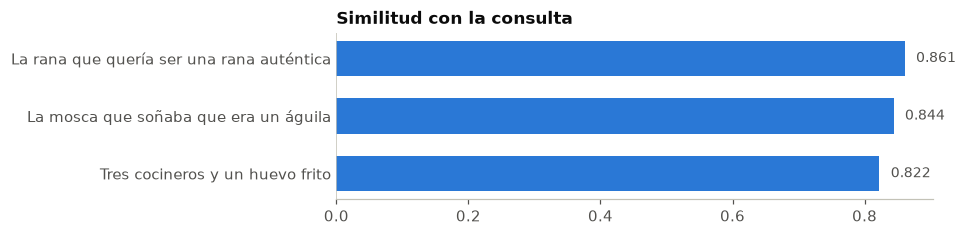

,fragmento,similitud
0,La rana que quería ser una rana auténtica,0.861
1,La mosca que soñaba que era un águila,0.844
2,Tres cocineros y un huevo frito,0.822


In [4]:
titulos_de_prueba = [
    "La rana que quería ser una rana auténtica",
    "La mosca que soñaba que era un águila",
    "Tres cocineros y un huevo frito",
]

nombres = []
similitudes = []
for titulo in titulos_de_prueba:
    filas = cuentos[cuentos["titulo"] == titulo]
    texto = filas.iloc[0]["texto"]
    vector_del_texto = embeddings.embed_documents([texto])[0]
    nombres.append(titulo)
    similitudes.append(float(np.dot(vector_de_consulta, vector_del_texto)))

utils.dibujar_barras(
    nombres, similitudes, titulo="Similitud con la consulta", formato="{:.3f}"
)
utils.tabla([
    {"fragmento": nombres[0], "similitud": round(similitudes[0], 3)},
    {"fragmento": nombres[1], "similitud": round(similitudes[1], 3)},
    {"fragmento": nombres[2], "similitud": round(similitudes[2], 3)},
])

> **Para mirar.**
>
> - El orden es el esperado: la rana (0,861), la mosca (0,844) y, al final, los cocineros (0,822).
> - Pero el texto de cocina, que no tiene relación con la consulta, también tiene una similitud alta. Con este modelo los valores absolutos se concentran en una franja angosta: el número sirve para **ordenar**, no para decidir si algo «se parece lo suficiente».

## 2. Guardar en ChromaDB

**ChromaDB** guarda, para cada fragmento, un identificador, el texto, los metadatos y el vector, y encuentra los vectores más cercanos a uno dado. Tres decisiones que conviene ver:

- **Persistencia.** `PersistentClient` guarda todo en una carpeta (`chroma_db/`), de modo que no hace falta recalcular los vectores cada vez.
- **Distancia.** Configuramos `cosine`: la distancia es `1 - similitud`, así que 0 es lo más cercano.
- **Los vectores los calculamos nosotros.** Si no se los pasamos, Chroma usa su propio modelo por defecto, que no es el nuestro. Es otra forma de mezclar modelos sin darse cuenta.

In [5]:
cliente = chromadb.PersistentClient(path=str(utils.RUTA_CHROMA))

# Empezamos de cero para que cada ejecucion del cuaderno parta igual.
for coleccion_vieja in ("cuentos", "cuentos_minilm"):
    try:
        cliente.delete_collection(coleccion_vieja)
    except Exception:
        pass

coleccion = cliente.get_or_create_collection(
    name="cuentos",
    configuration={"hnsw": {"space": "cosine"}},
    metadata={"modelo": utils.MODELO_EMBEDDINGS},
)

textos = list(cuentos["texto"])
vectores = embeddings.embed_documents(textos)

metadatos = []
for posicion in range(len(cuentos)):
    fila = cuentos.iloc[posicion]
    metadatos.append({"autor": fila["autor"], "titulo": fila["titulo"]})

coleccion.add(
    ids=list(cuentos["id"]),
    documents=textos,
    embeddings=vectores,
    metadatas=metadatos,
)
print(f"Fragmentos guardados: {coleccion.count()}")
print("Metadatos de la colección:", coleccion.metadata)

Fragmentos guardados: 137
Metadatos de la colección: {'modelo': 'intfloat/multilingual-e5-small'}


Consultamos con el vector de la consulta y pedimos los tres más cercanos (`n_results=3`). La respuesta de Chroma viene en listas dentro de listas, porque se pueden mandar varias consultas a la vez.

In [6]:
resultado = coleccion.query(
    query_embeddings=[vector_de_consulta], n_results=3
)

filas_de_resultado = []
for posicion in range(3):
    metadato = resultado["metadatas"][0][posicion]
    filas_de_resultado.append({
        "puesto": posicion + 1,
        "título": metadato["titulo"],
        "autor": metadato["autor"],
        "distancia": round(resultado["distances"][0][posicion], 3),
        "fragmento": resultado["documents"][0][posicion][:90],
    })
utils.tabla(filas_de_resultado)

,puesto,título,autor,distancia,fragmento
0,1,La rana que quería ser una rana auténtica,Augusto Monterroso,0.139,"Había una vez una rana que quería ser una rana auténtica, y todos los días se esforzaba en"
1,2,La rana que quería ser una rana auténtica,Augusto Monterroso,0.147,Por fin pensó que la única forma de conocer su propio valor estaba en la opinión de la gen
2,3,Noctilucas,Enrique Anderson Imbert,0.150,"El rostro era idéntico al de él, solo que embellecido por una luminosa sonrisa. FIN El Gat"


> **Para mirar.**
>
> - Los dos primeros resultados son fragmentos del mismo cuento, el de la rana que quería ser una rana auténtica; el tercero es «Noctilucas», de otro autor. La distancia va de 0,139 a 0,150.
> - «La mosca que soñaba que era un águila» no está entre los tres primeros aunque trata de algo parecido. Sin juicios previos de relevancia no podemos decir si falló la búsqueda o si la rana es mejor respuesta: eso se mide en el cuaderno 04.
> - Con este modelo las distancias de los primeros puestos son muy parecidas entre sí. El número solo sirve para ordenar, no para decidir «esto es suficientemente parecido».

In [7]:
# Un cliente nuevo sobre la misma carpeta: lo guardado sigue ahi.
cliente_nuevo = chromadb.PersistentClient(path=str(utils.RUTA_CHROMA))
coleccion_reabierta = cliente_nuevo.get_collection("cuentos")
print(f"Fragmentos al reabrir: {coleccion_reabierta.count()}")

Fragmentos al reabrir: 137


## 3. Filtrar por metadatos

El parámetro `where` limita la búsqueda a los fragmentos cuyos metadatos cumplen una condición. Buscamos lo mismo, pero solo entre los textos de Julio Cortázar.

In [8]:
resultado_filtrado = coleccion.query(
    query_embeddings=[vector_de_consulta],
    n_results=3,
    where={"autor": "Julio Cortázar"},
)

filas_filtradas = []
for posicion in range(3):
    metadato = resultado_filtrado["metadatas"][0][posicion]
    filas_filtradas.append({
        "puesto": posicion + 1,
        "título": metadato["titulo"],
        "autor": metadato["autor"],
        "distancia": round(resultado_filtrado["distances"][0][posicion], 3),
    })
utils.tabla(filas_filtradas)

,puesto,título,autor,distancia
0,1,Conservación de los recuerdos,Julio Cortázar,0.166
1,2,Instrucciones para llorar,Julio Cortázar,0.168
2,3,Instrucciones para subir una escalera,Julio Cortázar,0.175


> **Para mirar.** Con el filtro, los tres resultados son de Cortázar, pero quedaron más lejos de la consulta (0,166 a 0,175) que los tres de la sección 2 (0,139 a 0,150). Un filtro garantiza **de quién** es el texto, no que trate del tema: si no hay buenos candidatos, devuelve los menos malos.

### Microlaboratorio 1 — La función `buscar`

**Tarea.** Encapsular la consulta, con filtro opcional por autor.  
**Producto.** `buscar`, comprobada con una consulta con y sin filtro.  
**Antes de empezar.** Secciones 1 a 3.

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `vector` | el vector de la consulta, con el prefijo `query: ` | `embeddings.embed_query(consulta)` |
| (2) `filtro` | un diccionario con el autor, o `None` si no se pidió | `{"autor": autor}` cuando `autor` no es `None` |

**Comprobación.** Una consulta sobre cocina tiene que traer primero «Tres cocineros y un huevo frito»; con filtro, todos los resultados son del autor pedido.

> **Ayuda 1.** En la sección 1 usamos `embed_query` con la consulta.  
> **Ayuda 2.** `where=None` en Chroma significa «sin filtro»; en la sección 3 está el formato del diccionario.

In [9]:
def buscar(
    consulta: str, cantidad: int = 3, autor: str | None = None
) -> list[dict]:
    """Busca los fragmentos mas cercanos a una consulta.

    Args:
        consulta: Texto de la consulta.
        cantidad: Cuantos resultados devolver.
        autor: Si se pasa, solo se busca entre los textos de ese autor.

    Returns:
        Lista de diccionarios con titulo, autor, distancia y fragmento.
    """
    vector = vector_de_consulta  # COMPLETAR (1)
    filtro = None  # COMPLETAR (2)
    respuesta = coleccion.query(
        query_embeddings=[vector], n_results=cantidad, where=filtro
    )
    encontrados = []
    for posicion in range(len(respuesta["ids"][0])):
        metadato = respuesta["metadatas"][0][posicion]
        encontrados.append({
            "titulo": metadato["titulo"],
            "autor": metadato["autor"],
            "distancia": respuesta["distances"][0][posicion],
            "fragmento": respuesta["documents"][0][posicion],
        })
    return encontrados


titulos_esperados = []
for fila in filas_de_resultado:
    titulos_esperados.append(fila["título"])
sobre_cocina = buscar("Quién prepara la comida")
utils.comprobar(
    sobre_cocina[0]["titulo"] == "Tres cocineros y un huevo frito",
    "revisa (1): hay que calcular el vector de la consulta que recibe buscar",
)

con_filtro = buscar(consulta, autor="Julio Cortázar")
autores_filtrados = set()
for encontrado in con_filtro:
    autores_filtrados.add(encontrado["autor"])
utils.comprobar(
    autores_filtrados == {"Julio Cortázar"},
    "revisa (2): con autor, todos los resultados tienen que ser de ese autor",
)

Todavia no: revisa (1): hay que calcular el vector de la consulta que recibe buscar
Todavia no: revisa (2): con autor, todos los resultados tienen que ser de ese autor


## 4. Cuando el vector no es comparable

Los vectores de dos modelos distintos **no se pueden comparar entre sí**, aunque tengan la misma cantidad de números. `paraphrase-multilingual-MiniLM-L12-v2` (el modelo de la unidad 009) también produce 384. Armamos una segunda colección con ese modelo y la consultamos con el vector de `e5-small`. Antes de ejecutar, predecí: ¿Chroma da un error?

In [10]:
minilm = HuggingFaceEmbeddings(
    model_name="sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
    encode_kwargs={"normalize_embeddings": True},
)

coleccion_minilm = cliente.get_or_create_collection(
    name="cuentos_minilm",
    configuration={"hnsw": {"space": "cosine"}},
    metadata={"modelo": "paraphrase-multilingual-MiniLM-L12-v2"},
)
coleccion_minilm.add(
    ids=list(cuentos["id"]),
    documents=textos,
    embeddings=minilm.embed_documents(textos),
    metadatas=metadatos,
)

# Consulta equivocada: vector de e5-small contra una coleccion de MiniLM.
mezcla = coleccion_minilm.query(
    query_embeddings=[vector_de_consulta], n_results=3
)
# Consulta correcta: vector de MiniLM contra la coleccion de MiniLM.
correcta = coleccion_minilm.query(
    query_embeddings=[minilm.embed_query(consulta)], n_results=3
)

filas_de_mezcla = []
for posicion in range(3):
    filas_de_mezcla.append({
        "puesto": posicion + 1,
        "con el modelo equivocado": mezcla["metadatas"][0][posicion]["titulo"],
        "distancia (equivocado)": round(mezcla["distances"][0][posicion], 3),
        "con el modelo correcto": correcta["metadatas"][0][posicion]["titulo"],
        "distancia (correcto)": round(correcta["distances"][0][posicion], 3),
    })
utils.tabla(filas_de_mezcla)

,puesto,con el modelo equivocado,distancia (equivocado),con el modelo correcto,distancia (correcto)
0,1,El cocinero,0.840,El rinoceronte,0.438
1,2,El cocinero,0.845,La jirafa,0.462
2,3,El suicida,0.852,El rinoceronte,0.501


> **Para mirar.**
>
> - Chroma no dio error. Con el modelo equivocado devolvió «El cocinero», «El cocinero» y «El suicida» para una consulta sobre un animal que quiere ser otro, con distancias de 0,84 a 0,85.
> - Con el modelo correcto, la misma colección trae «El rinoceronte» y «La jirafa», con distancias de 0,44 a 0,50.
> - La única pista de que algo anda mal es una distancia mucho mayor que la habitual. Por eso conviene guardar el modelo junto al índice y verificarlo antes de consultar.

### Microlaboratorio 2 — No usar un índice con otro modelo

**Tarea.** Escribir una guarda que impida consultar una colección con un modelo distinto del que la construyó.  
**Producto.** `verificar_modelo` y `mi_decision`.  
**Antes de empezar.** Sección 4.

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `modelo_del_indice` | el modelo guardado al crear la colección | `coleccion_a_usar.metadata["modelo"]` |
| (2) condición del `if` | verdadera cuando el modelo del índice no es el esperado | comparar con `modelo_esperado` usando `!=` |
| Paso 3 | tu respuesta en `mi_decision` | al menos 30 palabras: **qué más conviene guardar junto al índice** para poder usarlo dentro de seis meses |

> **Ayuda 1.** En la sección 2 guardamos el modelo en `metadata` al crear la colección.  
> **Ayuda 2.** La función tiene que lanzar `ValueError` con un mensaje claro; la comprobación la atrapa.

In [11]:
def verificar_modelo(
    coleccion_a_usar: chromadb.Collection, modelo_esperado: str
) -> None:
    """Verifica que una coleccion se haya construido con el modelo esperado.

    Args:
        coleccion_a_usar: Coleccion de Chroma.
        modelo_esperado: Nombre del modelo con el que se va a consultar.

    Raises:
        ValueError: Si la coleccion se construyo con otro modelo.
    """
    modelo_del_indice = ""  # COMPLETAR (1)
    if False:  # COMPLETAR (2)
        raise ValueError(
            f"El indice se construyo con {modelo_del_indice} y se quiere "
            f"consultar con {modelo_esperado}."
        )


verificar_modelo(coleccion, utils.MODELO_EMBEDDINGS)
try:
    verificar_modelo(coleccion_minilm, utils.MODELO_EMBEDDINGS)
    rechazo = False
except ValueError:
    rechazo = True
utils.comprobar(
    rechazo,
    "revisa (1) y (2): la coleccion de MiniLM tiene que ser rechazada",
)

mi_decision = ""
utils.comprobar(
    len(mi_decision.split()) >= 30,
    "escribi al menos 30 palabras en mi_decision",
)

Todavia no: revisa (1) y (2): la coleccion de MiniLM tiene que ser rechazada
Todavia no: escribi al menos 30 palabras en mi_decision


## 5. La misma colección con LangChain

En un proyecto es habitual usar LangChain como capa por encima de Chroma. El envoltorio `Chroma` recibe la colección y el objeto de embeddings, y **calcula el vector de la consulta por nosotros** (con el prefijo `query: `). Lo que devuelve son `Document`, la estructura del cuaderno 01.

In [12]:
base_de_vectores = Chroma(
    client=cliente,
    collection_name="cuentos",
    embedding_function=embeddings,
)

con_langchain = base_de_vectores.similarity_search_with_score(consulta, k=3)

filas_de_langchain = []
for documento, distancia in con_langchain:
    filas_de_langchain.append({
        "título": documento.metadata["titulo"],
        "autor": documento.metadata["autor"],
        "distancia": round(distancia, 3),
    })
utils.tabla(filas_de_langchain)

,título,autor,distancia
0,La rana que quería ser una rana auténtica,Augusto Monterroso,0.139
1,La rana que quería ser una rana auténtica,Augusto Monterroso,0.147
2,Noctilucas,Enrique Anderson Imbert,0.150


In [13]:
titulos_de_langchain = []
for documento, distancia in con_langchain:
    titulos_de_langchain.append(documento.metadata["titulo"])
utils.comprobar(
    titulos_de_langchain == titulos_esperados,
    "LangChain y Chroma directo tienen que devolver los mismos tres titulos",
)

Correcto.


> **Para mirar.** LangChain no cambió el resultado: devolvió los mismos tres fragmentos con las mismas distancias. Lo que ahorra es el cálculo del vector de la consulta y la conversión a `Document`; lo que no ahorra es la responsabilidad de usar el mismo modelo y los mismos prefijos al guardar y al consultar. El objeto `base_de_vectores.as_retriever()` es lo que el cuaderno 03 le pasa al generador.

## Qué te llevás

- Un índice vectorial guarda **id, texto, metadatos y vector**. Los vectores los calcula un modelo, y solo se pueden comparar vectores del **mismo modelo y los mismos prefijos**.
- Mezclar modelos de igual dimensión **no da error**: da resultados sin sentido y distancias mucho más grandes de lo normal. Guardar el nombre del modelo junto al índice y verificarlo antes de consultar es una defensa barata.
- Los metadatos permiten filtrar y citar. LangChain agrega comodidad (vector de la consulta, `Document`), no garantías.

**Sigue:** cómo conectar la búsqueda con un modelo que redacte la respuesta y cite de dónde la sacó (cuaderno 03).